# NumPy Array Operations

*A practical notebook on array creation, indexing, shape manipulation, and broadcasting.*

In this chapter, we focus on four essential parts of NumPy: creating arrays, selecting data with indices and slices, changing array shapes, and using broadcasting for element-wise operations.

| Part | Key points | What you will learn |
|---|---|---|
| Array creation | `array`, `asarray`, `zeros`, `ones`, `full`, `empty`, `arange`, `linspace`, `eye` | Convert Python data into `ndarray` objects and create arrays with prescribed values |
| Indexing and slicing | Integer indices, slices, multidimensional indices, Boolean indexing, fancy indexing | Select elements and understand views versus copies |
| Shape manipulation | `reshape`, `ravel`, `flatten`, transpose, axis movement, `squeeze`, `expand_dims`, `concatenate`, `stack` | Change an array's structure while keeping track of its data |
| Broadcasting | Trailing-dimension alignment and dimension compatibility | Perform element-wise operations on arrays with compatible shapes |

**Learning tip:** Run each code cell in order. Before running it, predict the output and the resulting `shape` whenever possible.

## part1:array creation

### 1.1 create an array from a python list

One of the most common ways to create a NumPy array is to start with a Python list and convert it using `np.array()`.

In [ ]:
import numpy as np

a=np.array([2,4,6,8])
print(a)
print('shape of a:',a.shape)
b=np.array([1,2,3])
print(b)
print('shape of b:',b.shape)

A one-dimensional array with three elements has shape `(3,)`. The comma is part of Python's tuple notation; it does not indicate a second dimension.

Compare the following shapes:

- `(3,)`: one-dimensional array;
- `(1, 3)`: two-dimensional array with one row and three columns;
- `(3, 1)`: two-dimensional array with three rows and one column.

This distinction is important in linear algebra and broadcasting.

In [ ]:
import numpy as np
a=np.array([1,2,3])
b=np.array([[1,2,3]])
c=np.array([[1],[2],[3]])
d=np.array([[[1,2],[3,4]]])

for x in [a,b,c,d]:
    print('x:',x,'shape:',x.shape)

**Important:** A one-dimensional array is neither a row vector nor a column vector. An array with `shape == (3,)` has only one axis. Only `(1, 3)` represents a two-dimensional row-shaped array, while `(3, 1)` represents a two-dimensional column-shaped array.

## 1.2 differences between np.array and np.asarray

`np.array()` and `np.asarray()` both convert input data to an `ndarray`, but they express slightly different intentions. `np.array()` creates an array according to the requested options; `np.asarray()` returns an array representation and can reuse an existing ndarray when possible.

In [ ]:
x = np.array([1, 2, 3])
a = np.array(x)
b = np.asarray(x)

print(a,a is x)
print(b,b is x)

In this example, `a` and `b` contain the same values as `x`, but object identity may differ:

- `a is x` checks whether `a` and `x` are the exact same Python object.
- `b is x` is `True` here because `np.asarray(x)` can return the original array when no conversion is needed.
- `a == x` compares elements and returns a Boolean array; it does **not** test object identity.

Use `np.array_equal(a, x)` to test whether two arrays contain equal values.

## 1.3 create an array with given initial value

When you know an array's shape but want to initialize it in a particular way, use `np.zeros`, `np.ones`, `np.full`, or `np.empty`.

In [ ]:
import numpy as np
z = np.zeros((2, 3))        # 全 0
o = np.ones((2, 3))         # 全 1
f = np.full((2, 3), 7)      # 全部填 7
e = np.empty((2, 3))        # 分配空间，但不初始化值

print(z)
print(o)
print(f)
print(e,\
      e.shape,\
      e.dtype)

`zeros`, `ones`, and `full` initialize every element to an explicit value. `empty` only allocates memory; its entries contain whatever values happen to be present in that memory. Never rely on those values. Assign every element before reading from an array created with `np.empty`.

| Function | Parameters | Endpoint behavior |
|---|---|---|
| `np.arange(start, stop, step)` | Start, stop, and step size | Normally excludes `stop` |
| `np.linspace(start, stop, num)` | Start, stop, and number of samples | Includes `stop` by default; configurable with `endpoint=False` |

For floating-point sampling, prefer `np.linspace` when you need a specified number of evenly spaced points. Floating-point representation can make `np.arange(0, 1, 0.1)` behave less predictably than expected.

In [ ]:
t = np.linspace(0.0, 2.0,5)
print(t)
print(len(t))

# endpoint=False 时不包含右端点
u = np.linspace(0.0, 1.0, 4, endpoint=False)
print(u)

## 1.4 Data types (`dtype`)

A NumPy array has a data type that determines how its elements are represented. Inspect it with `a.dtype`. You can request a type during creation or convert an existing array with `astype()`.

For numerical work, choose a type deliberately when precision or complex numbers matter. Quantum-state vectors and quantum-gate matrices, for example, should use a complex dtype such as `np.complex128` when they may contain imaginary components.

In [ ]:
real_array = np.array([1, 2, 3], dtype=np.float64)
complex_array = np.array([1, 2j, 3], dtype=np.complex128)
converted = real_array.astype(np.complex128)

print(real_array.dtype)
print(complex_array.dtype)
print(converted)


## 1.5 common matrix: eye and identity

In [ ]:
I1 = np.eye(3)
I2 = np.identity(3)

print(I1)
print(np.array_equal(I1, I2))

# eye can also specify the matrix offset
A = np.eye(3, 4, k=-1)
print(A)

`np.eye(m, n, k)` creates an `m × n` array with ones on the diagonal offset by `k`. `np.identity(n)` creates an `n × n` identity matrix. These functions are especially useful in linear algebra.

# Part 2: Indexing and slicing

## 2.1 one-dimensional array:integer indices and negative indices

In [ ]:
import numpy as np
a = np.array([10, 20, 30, 40, 50])
print(a[0])    # 10
print(a[2])    # 30
print(a[-1])   # 50
print(a[-2])   # 40

For an array of length 5, valid positive indices are `0` through `4`, and valid negative indices are `-5` through `-1`. Accessing `a[5]` or `a[-6]` raises an `IndexError`.

## 2.2 slicing: start:stop:step

In [ ]:
a = np.array([0, 1, 2, 3, 4, 5, 6, 7])

print(a[2:6])     # [2 3 4 5]
print(a[:4])      # [0 1 2 3]
print(a[4:])      # [4 5 6 7]
print(a[::2])     # [0 2 4 6]
print(a[::-1])

| Expression | Meaning |
|---|---|
| `a[2:6]` | Elements at indices 2, 3, 4, and 5 |
| `a[:4]` | Elements from the beginning up to (but not including) index 4 |
| `a[3:]` | Elements from index 3 to the end |
| `a[::2]` | Every second element |
| `a[::-1]` | Elements in reverse order |

## 2.3 two-dimensional array : write indices for eac axis

For a two-dimensional array, use `a[row, column]`. The index before the comma addresses axis 0 (rows); the index after the comma addresses axis 1 (columns).

In [ ]:
A = np.array([[10, 11, 12, 13],
              [20, 21, 22, 23],
              [30, 31, 32, 33]])

print(A[1, 2])
print(A[1, :])
print(A[:, 2])
print(A[:2, 1:3])

Integer indexing removes the indexed axis from the result. To preserve a two-dimensional shape, use a slice of length one, such as `A[1:2, :]` instead of `A[1, :]`.

## 2.4 three-dimensional arrays and ellipses

A three-dimensional array can be viewed as a stack of two-dimensional arrays. Indices from left to right address axes 0, 1, and 2. The ellipsis `...` stands for as many full slices (`:`) as needed to cover unspecified axes.

In [ ]:
X = np.arange(2 * 3 * 4).reshape(2, 3, 4)
print(X)
print(X.shape)       # (2, 3, 4)
print(X[0, :, :].shape)  # (3, 4)
print(X[:, :, 0].shape)  # (2, 3)
print(X[..., 0].shape)   #  X[:, :, 0]

## 2.5 add a new one-dimensional axis :none/np.newaxis

`None` and `np.newaxis` are equivalent in indexing. They insert a new axis without copying or adding data; the array gets a different shape.

In [ ]:
import numpy as np

v = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

row = v[np.newaxis, :, :]   # shape: (1, 2, 3)
col = v[:, :, np.newaxis]   # shape: (2, 3, 1)

print("row:", row.shape)
print("col:", col.shape)

`np.newaxis` is especially useful in broadcasting. For a two-dimensional array, `v[np.newaxis, :, :]` adds a leading axis, while `v[:, :, np.newaxis]` adds a trailing axis. The positions of the new axes matter.

## 2.6 fancy indexing:use integers to select position

If an integer list or integer array is used as an index, NumPy selects elements at the specified positions. This is called **fancy indexing** (or integer-array indexing).

In [ ]:
import numpy as np
a=np.array([10,20,30,40,50,60,70,80])
idx=[0,2,0,2,4,6]

print(a,a[idx])

Fancy indexing can select the same element more than once. Unlike basic slicing, fancy indexing generally returns a copy rather than a view. Modifying the result therefore does not modify the original array.

## 2.7 bool indexing:use conditions to select elements

Boolean indexing uses a Boolean array to select elements for which the corresponding condition is `True`.

In [ ]:
import numpy as np
a=np.array([1,2,3,4,5,6,7,8,9])
cond1=(a<5)
cond2=(a>2) & (a<6)
print(cond1,a[cond1])
print(cond2,a[cond2])

To combine element-wise Boolean conditions, use `&` (and), `|` (or), and `~` (not). Put each comparison in parentheses. Do not use Python's scalar `and` or `or` with NumPy Boolean arrays.

# Part 3: Shape manipulation

## 3.1reshape:reshape the array and conserve the data

In [ ]:
import numpy as np
a = np.arange(12)
B = a.reshape(3, 4)
C = a.reshape(2, 2, 3)

print(B)
print(B.shape)
print(C.shape)

The product of the dimensions in the new shape must equal the original number of elements. For example, an array with 12 elements can be reshaped to `(3, 4)` or `(2, 2, 3)`, but not `(5, 5)`.

You can use `-1` for at most one dimension and let NumPy infer its size.

In [ ]:
a = np.arange(24)
B = a.reshape(4, -1)
C = a.reshape(-1, 3)

print(B.shape)  # (4, 6)
print(C.shape)  # (8, 3)

At most one dimension in a `reshape` target can be `-1`. NumPy infers that dimension from the total number of elements. Multiple `-1` entries are ambiguous and are not allowed.

## 3.2 reshape:order parameter

In [ ]:
a = np.arange(1, 7)

print(a.reshape(2, 3, order="C"))
print(a.reshape(2, 3, order="F"))

With `order="C"`, elements are traversed with the last axis changing fastest (row-major order). With `order="F"`, the first axis changes fastest (column-major order).

The `order` argument describes the logical order used to read and place elements during reshaping. It does not guarantee the physical memory layout or contiguity of the returned array.

## 3.3 `flatten` and `ravel`: convert to one dimension

Both `flatten()` and `ravel()` return a one-dimensional array containing the elements of the original array.

- `flatten()` always returns a copy.
- `ravel()` returns a view when possible, but may return a copy depending on memory layout.

Use `np.shares_memory(a, b)` to check whether two arrays share memory; do not assume that `ravel()` always returns a view.

## 3.4 `swapaxes` and `moveaxis`

In [ ]:
X=np.zeros((2, 3,4))
Y=np.swapaxes(X, 0, 2)
Z=np.moveaxis(X, 0, -1)
print(X)
print(Y)
print(Z)


| Operation | Meaning | Example |
|---|---|---|
| `np.swapaxes(a, 0, 2)` | Exchange two existing axes | Swap axes 0 and 2 |
| `np.moveaxis(a, 0, -1)` | Move one axis to a new position; the relative order of other axes is preserved | Move axis 0 to the last position |

## 3.5 `squeeze` and `expand_dims`

`np.squeeze` removes axes whose length is 1. `np.expand_dims` inserts a new axis at the specified position. When using `squeeze(axis=...)`, the selected axis must have length 1.

In [ ]:
a = np.zeros((1, 3, 1, 4))
b = np.squeeze(a)
c = np.squeeze(a, axis=0)
d = np.expand_dims(np.array([1, 2, 3]), axis=1)

print(a.shape)  # (1, 3, 1, 4)
print(b.shape)  # (3, 4)
print(c.shape)  # (3, 1, 4)
print(d.shape)  # (3, 1)

## 3.6 Transpose

For a two-dimensional array, `.T` swaps rows and columns. For an array with more than two dimensions, `.T` reverses the order of all axes. Use `np.transpose(a, axes=...)` when you need to specify a particular axis order.

Remember that transpose changes the arrangement of axes, not the underlying mathematical values.

In [ ]:
A = np.arange(6).reshape(2, 3)
print(A)
print("transpose:")
print(A.T)
print("shape:", A.T.shape)


## 3.7 `concatenate` and `stack`

`np.concatenate` joins arrays along an existing axis. `np.stack` joins arrays along a **new** axis. For `concatenate`, dimensions other than the concatenation axis must match; for `stack`, all input shapes must match.

In [ ]:
import numpy as np
a = np.array([[1, 2],
              [3, 4]])
b = np.array([[5, 6],
              [7, 8]])

cat0 = np.concatenate([a, b], axis=0)
cat1 = np.concatenate([a, b], axis=1)
stk0 = np.stack([a, b], axis=0)

print(cat0,cat0.shape)  # (4, 2)
print(cat1,cat1.shape)  # (2, 4)
print(stk0,stk0.shape)  # (2, 2, 2)

# Part 4: Broadcasting

## 4.1 why broadcasting?

Broadcasting allows NumPy to perform element-wise operations on arrays with different but compatible shapes, without manually repeating the smaller array.

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])
b = np.array([10, 20, 30])

C = A + b
print(C)

## 4.2 The two rules of broadcasting

**Rule 1: Align dimensions from the right.** If the arrays have different numbers of dimensions, conceptually pad the shape of the lower-dimensional array with leading dimensions of length 1.

**Rule 2: Compare each pair of dimensions.** The dimensions are compatible if they are equal or if at least one of them is 1. If neither condition holds for any pair, broadcasting fails.

For example, shapes `(2, 3)` and `(3,)` are compatible: `(3,)` is aligned as `(1, 3)`, then broadcast across the two rows. Shapes `(2, 3)` and `(2,)` are not compatible because the trailing dimensions 3 and 2 differ.

### A visual way to check broadcasting

```text
A.shape = (2, 3)       -> (2, 3)
b.shape = (3,)         -> (1, 3)  # conceptual leading 1
                         -------
                         (2, 3)  # result shape
```

The smaller array is conceptually expanded along the leading axis; NumPy does not need to physically copy its values just to perform the operation.
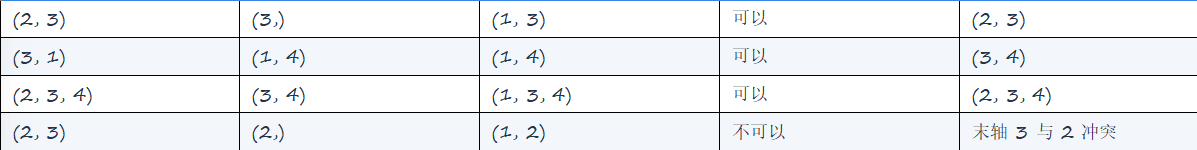

In [ ]:
# A second broadcasting example: column vector + row vector
column = np.array([[10], [20]])   # shape (2, 1)
row = np.array([1, 2, 3])         # shape (3,)
result = column + row

print("column shape:", column.shape)
print("row shape:", row.shape)
print("result shape:", result.shape)
print(result)

# A shape mismatch raises ValueError; demonstrate it safely.
try:
    _ = np.zeros((2, 3)) + np.zeros((2,))
except ValueError as exc:
    print("Incompatible shapes:", exc)
